# **Project Name :- Air Temperature Time Series**


## Objective
To analyze monthly mean temperature data and build a time series forecasting model to predict future temperatures.

## Feature Details
- Month: Month for which the mean temperature is recorded.
- Mean_temp: Average temperature recorded for the month.

# Introduction

Time series forecasting is used to predict future values based on historical observations.

In this project, historical monthly mean air temperature data is analyzed to identify trends and seasonal patterns. Different forecasting models including ARIMA, SARIMA, and LSTM are developed and evaluated to forecast future monthly mean air temperature.

# Problem Statement

Develop a machine learning forecasting model that can predict monthly mean air temperature for upcoming months based on historical temperature observations.

# 1. Import Libraries

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully")

Libraries imported successfully


# 2. Download Dataset

In [2]:
import requests

url = "https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Capstone-Projects/PRAICP-1003-AirTempTS.zip"

response = requests.get(url)

with open("/content/PRAICP-1003-AirTempTS.zip", "wb") as f:
    f.write(response.content)

print("ZIP downloaded successfully!")

ZIP downloaded successfully!


# 3. Extract ZIP

In [3]:
import zipfile
import os

zip_path = "/content/PRAICP-1003-AirTempTS.zip"
extract_path = "/content/air_temperature"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    print(root, files[:5])

Dataset extracted successfully!
/content/air_temperature []
/content/air_temperature/Data ['Copy of metadata-surface-air-temperature-monthly-mean.txt', 'surface-air-temperature-monthly-mean.csv']


# 4. Finding CSV File

In [5]:
import glob

csv_files = glob.glob("/content/air_temperature/**/*.csv", recursive=True)

print("CSV files found:")
for file in csv_files:
    print(file)

CSV files found:
/content/air_temperature/Data/surface-air-temperature-monthly-mean.csv


# 5. Load Dataset

In [6]:
df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,month,mean_temp
0,1982-01,25.9
1,1982-02,27.1
2,1982-03,27.2
3,1982-04,27.0
4,1982-05,28.0


# 5.1 Basic Dataset Understanding

In [7]:
print("Shape of dataset:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Shape of dataset: (462, 2)

Columns:
Index(['month', 'mean_temp'], dtype='object')

Data Types:
month         object
mean_temp    float64
dtype: object

First 5 rows:


,month,mean_temp
0,1982-01,25.9
1,1982-02,27.1
2,1982-03,27.2
3,1982-04,27.0
4,1982-05,28.0


# 6. Checking Missing Values

In [8]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
month        0
mean_temp    0
dtype: int64

Duplicate rows: 0


# 7. Dataset Information

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 462 entries, 0 to 461
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   month      462 non-null    object 
 1   mean_temp  462 non-null    float64
dtypes: float64(1), object(1)
memory usage: 7.3+ KB


#  Statistics Summary

In [10]:
df.describe()

,mean_temp
count,462.000000
mean,27.665152
std,0.808186
min,25.400000
25%,27.100000
50%,27.700000
75%,28.300000
max,29.500000


# 8. Convert Month to Date/Time

In [11]:
df['month'] = pd.to_datetime(df['month'])

df = df.sort_values('month')

df.head()

,month,mean_temp
0,1982-01-01,25.9
1,1982-02-01,27.1
2,1982-03-01,27.2
3,1982-04-01,27.0
4,1982-05-01,28.0


# Set Month as Index

In [12]:
df.set_index('month', inplace=True)

df.head()

,mean_temp
month,
1982-01-01,25.9
1982-02-01,27.1
1982-03-01,27.2
1982-04-01,27.0
1982-05-01,28.0


# Check Time Range

In [13]:
print("Start date:", df.index.min())
print("End date:", df.index.max())
print("Number of records:", len(df))

Start date: 1982-01-01 00:00:00
End date: 2020-06-01 00:00:00
Number of records: 462


# 9. Exploratory Data Analysis (EDA)

# 9.1 Temperature Trend

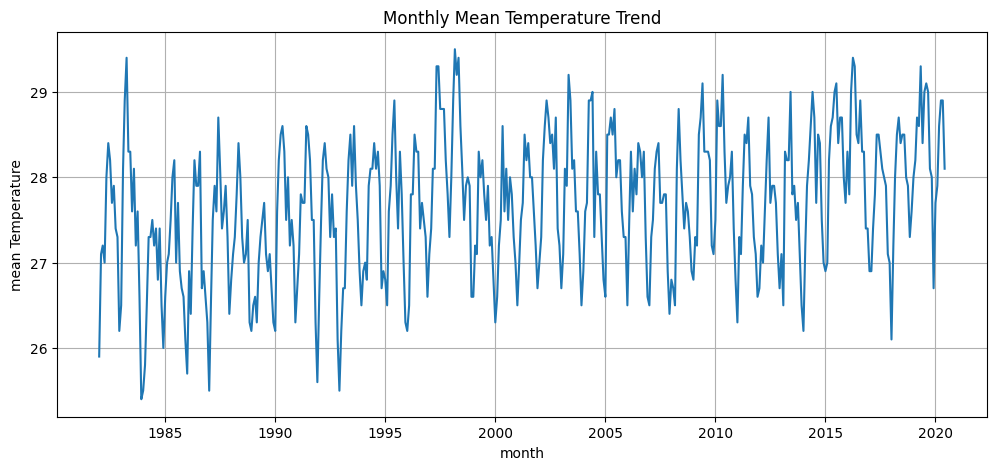

In [14]:
plt.figure(figsize=(12,5))

plt.plot(df.index, df['mean_temp'])

plt.xlabel("month")
plt.ylabel("mean Temperature")
plt.title("Monthly Mean Temperature Trend")

plt.grid(True)
plt.show()

### Analysis

The time series plot shows the variation in mean temperature over different months. The temperature pattern can be analyzed to identify seasonal variations and long-term trends.

# 9.2 Temperature Distribution

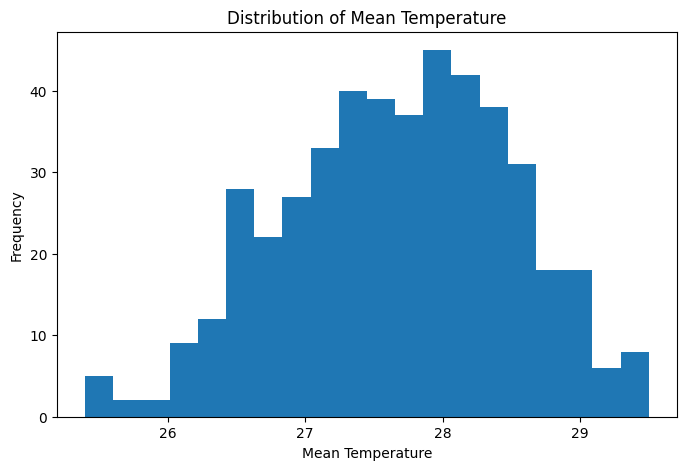

In [15]:
plt.figure(figsize=(8,5))

plt.hist(df['mean_temp'], bins=20)

plt.xlabel("Mean Temperature")
plt.ylabel("Frequency")
plt.title("Distribution of Mean Temperature")

plt.show()

# 9.3 Monthly Seasonal Pattern

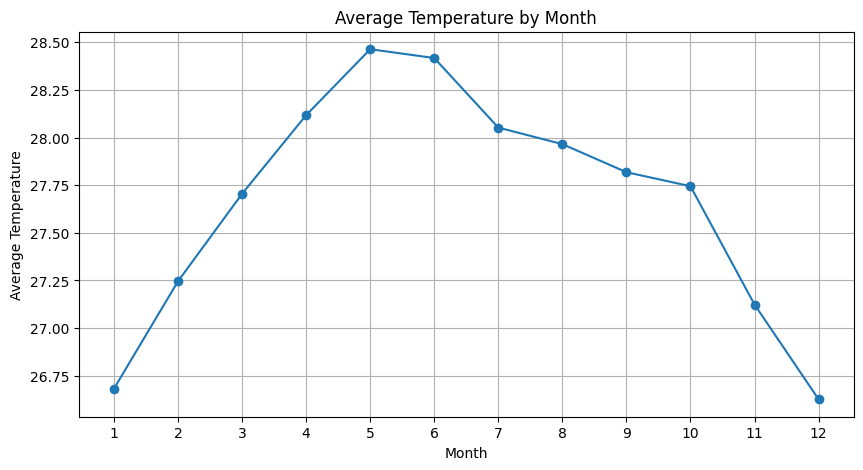

In [16]:
monthly_avg = df.groupby(df.index.month)['mean_temp'].mean()

plt.figure(figsize=(10,5))

plt.plot(monthly_avg.index, monthly_avg.values, marker='o')

plt.xlabel("Month")
plt.ylabel("Average Temperature")
plt.title("Average Temperature by Month")

plt.xticks(range(1,13))
plt.grid(True)

plt.show()

## Seasonal Analysis

The monthly average temperature plot helps identify recurring seasonal patterns. Since the observations are monthly, a seasonal cycle of approximately 12 months can be considered for seasonal forecasting models such as SARIMA.

# 10. Data Preparation

# Check Data Again

In [17]:
print(df.head())
print(df.tail())

print("Missing values:")
print(df.isnull().sum())

            mean_temp
month                
1982-01-01       25.9
1982-02-01       27.1
1982-03-01       27.2
1982-04-01       27.0
1982-05-01       28.0
            mean_temp
month                
2020-02-01       27.9
2020-03-01       28.6
2020-04-01       28.9
2020-05-01       28.9
2020-06-01       28.1
Missing values:
mean_temp    0
dtype: int64


# 11. Train-Test Split

In [18]:
train_size = int(len(df) * 0.8)

train = df['mean_temp'].iloc[:train_size]
test = df['mean_temp'].iloc[train_size:]

print("Training data:", len(train))
print("Testing data:", len(test))

Training data: 369
Testing data: 93


# Visualize Train & Test

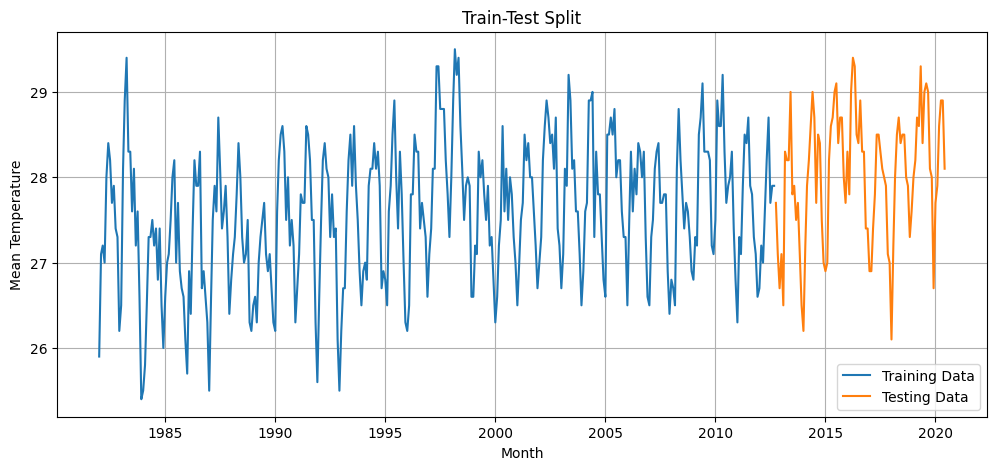

In [19]:
plt.figure(figsize=(12,5))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Testing Data")

plt.xlabel("Month")
plt.ylabel("Mean Temperature")
plt.title("Train-Test Split")

plt.legend()
plt.grid(True)

plt.show()

## Train-Test Split

The dataset was divided chronologically into training and testing datasets.

Approximately 80% of the historical observations were used for training the models, while the remaining 20% were used for testing.

A chronological split was used instead of random splitting because time series observations are dependent on their temporal order.

# 12. ARIMA Model

# 12.1 Build ARIMA Model

In [20]:
model = ARIMA(train, order=(1,1,1))

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:              mean_temp   No. Observations:                  369
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -332.110
Date:                Mon, 28 Sep 2026   AIC                            670.220
Time:                        09:05:23   BIC                            681.945
Sample:                    01-01-1982   HQIC                           674.878
                         - 09-01-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9812      0.024    -40.277      0.000      -1.029      -0.933
ma.L1          0.9522      0.038     24.881      0.000       0.877       1.027
sigma2         0.3557      0.028     12.820      0.0

# 12.2 Make Predictions

In [21]:
 predictions = model_fit.forecast(steps=len(test))

 predictions = pd.Series(
    predictions,
    index=test.index
)

predictions.head()

,predicted_mean
month,
2012-10-01,27.974843
2012-11-01,27.901411
2012-12-01,27.973459
2013-01-01,27.902769
2013-02-01,27.972126


# 12.3 Compare Actual vs Predicted

In [22]:
comparison = pd.DataFrame({
    'Actual': test,
    'Predicted': predictions
})

comparison.head(10)

,Actual,Predicted
month,,
2012-10-01,27.7,27.974843
2012-11-01,27.1,27.901411
2012-12-01,26.7,27.973459
2013-01-01,27.1,27.902769
2013-02-01,26.5,27.972126
2013-03-01,28.3,27.904076
2013-04-01,28.2,27.970843
2013-05-01,28.2,27.905335
2013-06-01,29.0,27.969609


# 12.4 Actual vs Predicted Graph

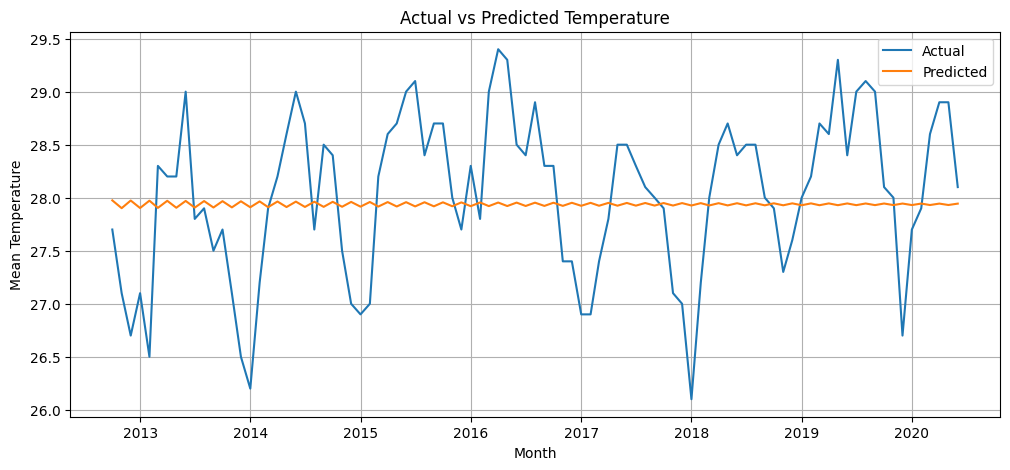

In [23]:
plt.figure(figsize=(12,5))

plt.plot(test.index, test, label="Actual")
plt.plot(predictions.index, predictions, label="Predicted")

plt.xlabel("Month")
plt.ylabel("Mean Temperature")
plt.title("Actual vs Predicted Temperature")

plt.legend()
plt.grid(True)

plt.show()

## ARIMA Model

ARIMA was implemented as a baseline time series forecasting model.

The model was trained using historical temperature observations and used to predict the values in the testing period.

The predicted values were compared with the actual temperature values to evaluate forecasting performance.

# 13. SARIMA

# 13.1 SARIMA BUILD

In [24]:
model = SARIMAX(train, order=(1,1,1), seasonal_order=(1,1,1,12))

model_fit = model.fit()

print(model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                          mean_temp   No. Observations:                  369
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -213.346
Date:                            Mon, 28 Sep 2026   AIC                            436.691
Time:                                    09:05:39   BIC                            456.066
Sample:                                01-01-1982   HQIC                           444.398
                                     - 09-01-2012                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3070      0.073      4.198      0.000       0.164       0.450
ma.L1         -0.8184      0.048   

# 13.2 Make Predictions

In [25]:
sarima_predictions = model_fit.forecast(steps=len(test))

sarima_predictions = pd.Series(
    sarima_predictions,
    index=test.index
)

sarima_predictions.head()

,predicted_mean
month,
2012-10-01,27.700024
2012-11-01,27.059602
2012-12-01,26.512059
2013-01-01,26.578246
2013-02-01,27.233689


# 13.3 Compare ARIMA vs SARIMA Predictions

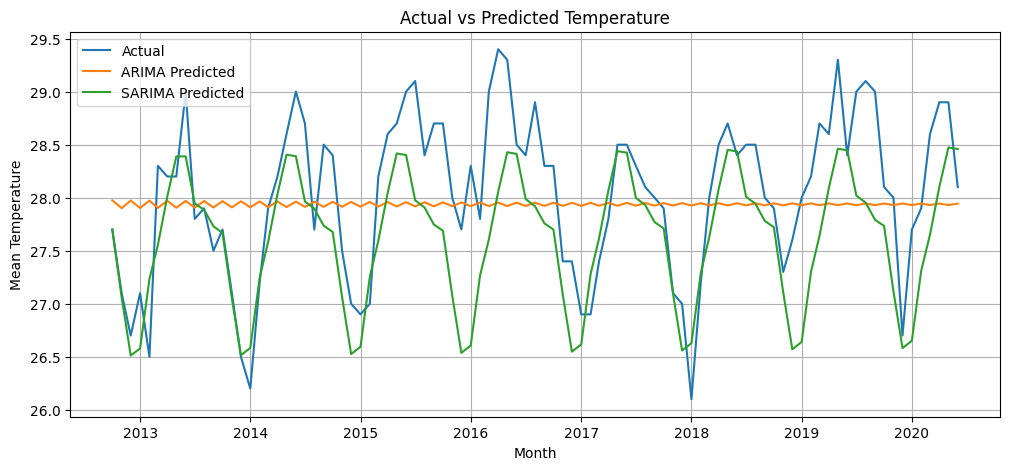

In [26]:
plt.figure(figsize=(12,5))

plt.plot(test.index, test, label="Actual")
plt.plot(predictions.index, predictions, label="ARIMA Predicted")
plt.plot(sarima_predictions.index, sarima_predictions, label="SARIMA Predicted")

plt.xlabel("Month")
plt.ylabel("Mean Temperature")
plt.title("Actual vs Predicted Temperature")

plt.legend()
plt.grid(True)

plt.show()

## SARIMA Model

SARIMA was implemented to account for both time series behavior and seasonal patterns in the monthly temperature data.

Since the dataset contains monthly observations, a seasonal period of 12 months was considered.

The SARIMA model was evaluated on the same testing dataset used for the other models.

# 14. LSTM Model

# 14.1 Preapring LSTM Data

In [27]:
time_steps = 12

print("Time steps:", time_steps)

Time steps: 12


In [28]:
temperatures = df['mean_temp'].values

scaler = MinMaxScaler(feature_range=(0,1))
scaled_temp = scaler.fit_transform(temperatures.reshape(-1,1))

train_size = int(len(scaled_temp) * 0.8)

train_data = scaled_temp[:train_size]
test_data = scaled_temp[train_size:]

print("Training data:", len(train_data))
print("Testing data:", len(test_data))

def create_dataset(dataset, look_back=1):
    X, Y = [], []
    for i in range(len(dataset) - look_back
                   - 1):
        a = dataset[i:(i + look_back), 0]
        X.append(a)
        Y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(Y)

    time_steps = 12

X_train, y_train = create_dataset(train_data, time_steps)
X_test, y_test = create_dataset(test_data, time_steps)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data: 369
Testing data: 93
X_train shape: (356, 12)
y_train shape: (356,)
X_test shape: (80, 12)
y_test shape: (80,)
Training data shape: (356, 12, 1)
Testing data shape: (80, 12, 1)


# 14.2 Build LSTM

In [29]:
lstm_model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(time_steps, 1)
    ),

    Dropout(0.2),

    LSTM(32),

    Dropout(0.2),

    Dense(1)
])

lstm_model.compile(
    optimizer='adam',
    loss='mse'
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 12, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

# 14.3 Train LSTM

In [30]:
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.1133 - val_loss: 0.0321
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0495 - val_loss: 0.0337
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0453 - val_loss: 0.0370
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0427 - val_loss: 0.0307
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0408 - val_loss: 0.0317
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0403 - val_loss: 0.0321
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0421 - val_loss: 0.0298
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0430 - val_loss: 0.0292
Epoch 9/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0394 - val_loss: 0.0287
Epoch 10/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0382 - val_loss: 0.0285
Epoch 11/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0405 - val_loss: 0.0273
Epoch 12/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0

# 14.4 Prepare LSTM Test Data

In [31]:
combined = pd.concat((df['mean_temp'], test), axis=0)

inputs = combined[len(combined) - len(test) - time_steps - 1:].values
inputs = inputs.reshape(-1,1)
inputs = scaler.transform(inputs)

X_test, y_test = create_dataset(inputs, time_steps)

X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (93, 12, 1)
y_test shape: (93,)


# 14.5 LSTM Prediction

In [32]:
lstm_pred_scaled = lstm_model.predict(
    X_test
)

lstm_pred = scaler.inverse_transform(
    lstm_pred_scaled
).flatten()

print("LSTM predictions:")
print(lstm_pred[:10])

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step
LSTM predictions:
[28.633795 28.596876 28.18566  27.62687  27.126806 27.021137 26.989908
 27.640799 28.152117 28.508018]


## LSTM Model

An LSTM-based deep learning model was developed to learn sequential patterns from historical temperature data.

The temperature values were scaled before training the LSTM model. A sequence of previous monthly observations was used to predict the next temperature value.

The model was then evaluated on the testing dataset.

# 15. Model Evaluation

# 15.1 MAE & RMSE

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Actual test values
actual = test.values

# MAE and RMSE for all models
arima_mae = mean_absolute_error(actual, np.array(predictions))
arima_rmse = np.sqrt(mean_squared_error(actual, np.array(predictions)))

sarima_mae = mean_absolute_error(actual, np.array(sarima_predictions))
sarima_rmse = np.sqrt(mean_squared_error(actual, np.array(sarima_predictions)))

lstm_mae = mean_absolute_error(actual, np.array(lstm_pred))
lstm_rmse = np.sqrt(mean_squared_error(actual, np.array(lstm_pred)))

print("ARIMA MAE:", arima_mae)
print("ARIMA RMSE:", arima_rmse)
print("SARIMA MAE:", sarima_mae)
print("SARIMA RMSE:", sarima_rmse)
print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)


ARIMA MAE: 0.6271050335797184
ARIMA RMSE: 0.7571495611206567
SARIMA MAE: 0.5076436838473694
SARIMA RMSE: 0.6371942473222861
LSTM MAE: 0.6020242875622165
LSTM RMSE: 0.7329503358446352


# 15.2 Evaluation Summary

In [34]:
evaluation_summary = pd.DataFrame({
    'Model': ['ARIMA', 'SARIMA', 'LSTM'],
    'MAE': [arima_mae, sarima_mae, lstm_mae],
    'RMSE': [arima_rmse, sarima_rmse, lstm_rmse]
})

evaluation_summary

,Model,MAE,RMSE
0,ARIMA,0.627105,0.757150
1,SARIMA,0.507644,0.637194
2,LSTM,0.602024,0.732950


## Model Evaluation

ARIMA, SARIMA, and LSTM were evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

MAE measures the average absolute difference between actual and predicted values.

RMSE measures the square root of the average squared prediction error and gives greater importance to larger errors.

Lower MAE and RMSE values indicate lower forecasting error.

# 16. Compare All Models

# 16.1 Model Comparison Graph

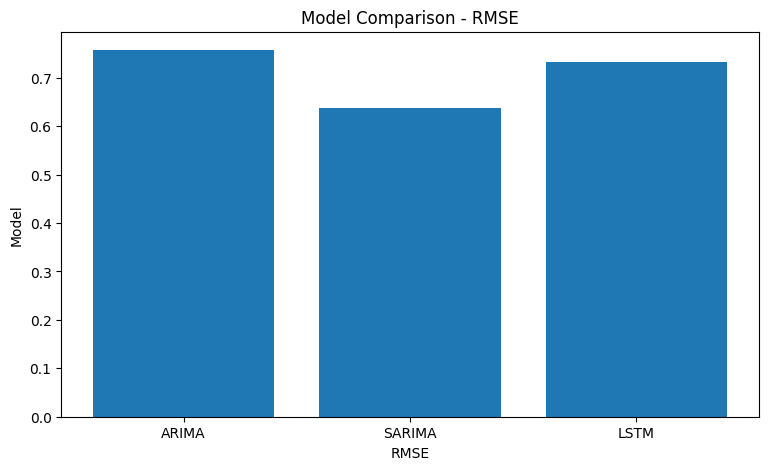

In [35]:
plt.figure(figsize=(9,5))

plt.bar(
    evaluation_summary['Model'],
    evaluation_summary['RMSE']
)

plt.title("Model Comparison - RMSE")
plt.ylabel("Model")
plt.xlabel("RMSE")

plt.show()

## Model Comparison

ARIMA, SARIMA, and LSTM were evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

Lower MAE and RMSE values indicate lower forecasting error. The model with the lowest error on the test dataset will be selected as the final forecasting model.

# 16.2 Actual VS All Predictions

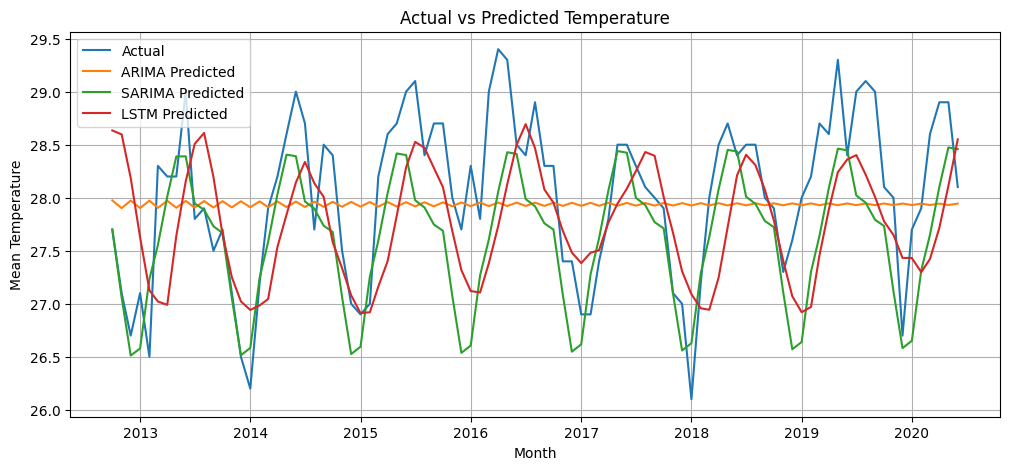

In [36]:
plt.figure(figsize=(12,5))

plt.plot(test.index, test, label="Actual")

plt.plot(
    predictions.index,
    predictions,
    label="ARIMA Predicted"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions,
    label="SARIMA Predicted"
)

plt.plot(
    pd.Series(
        lstm_pred,
        index=test.index
    ),
    label="LSTM Predicted"
)

plt.xlabel("Month")
plt.ylabel("Mean Temperature")
plt.title("Actual vs Predicted Temperature")

plt.legend()
plt.grid(True)

plt.show()

# 16.3 Select Best Model

In [40]:
best_model_name = evaluation_summary.loc[
    evaluation_summary['RMSE'].idxmin(),
    'Model'
]

print("Selected Model:", best_model_name)


Selected Model: SARIMA


## Best Model Selection

SARIMA was selected as the final model because it achieved the lowest forecasting error among the ARIMA, SARIMA, and LSTM models based on the evaluation results.

The model comparison was performed using MAE and RMSE on the same testing dataset.

SARIMA was particularly suitable for this project because the data consists of monthly temperature observations and shows recurring seasonal patterns.

Therefore, SARIMA was selected as the final model for forecasting future monthly mean air temperature.

## Why SARIMA Was Selected?

SARIMA was selected based on both model evaluation results and the characteristics of the dataset.

The temperature data contains monthly observations with recurring seasonal behavior. SARIMA extends ARIMA by incorporating seasonal components, making it suitable for time series data with repeating seasonal patterns.

Among the three evaluated models, SARIMA produced the lowest forecasting error according to the model comparison results.

Therefore, SARIMA was selected for the final 12-month temperature forecast.

# Train Final Model on Full Dataset

In [38]:
full_series = df['mean_temp']

# 17. Future Forecast

# 17.1 Forecast Function

In [41]:
forecast_steps = 12

def get_statistical_forecast(model_instance, steps):
    model_fit = model_instance.fit(
        disp=False,
        maxiter=200
    )

    forecast_values = model_fit.forecast(
        steps=steps
    )

    return forecast_values

# Final Forecast


In [42]:
print("Selected Model: SARIMA - Training Final Model and Forecasting...")

model_sarima = SARIMAX(
    full_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

future_forecast = get_statistical_forecast(
    model_sarima,
    forecast_steps
)

print("SARIMA forecast generated successfully!")
print(future_forecast)

Selected Model: SARIMA - Training Final Model and Forecasting...
SARIMA forecast generated successfully!
2020-07-01    28.335835
2020-08-01    28.369600
2020-09-01    28.246123
2020-10-01    28.177146
2020-11-01    27.557025
2020-12-01    27.059868
2021-01-01    27.136207
2021-02-01    27.689839
2021-03-01    28.146773
2021-04-01    28.559178
2021-05-01    28.905255
2021-06-01    28.859052
Freq: MS, Name: predicted_mean, dtype: float64


# 17.2 Future Dates

In [43]:
future_dates = pd.date_range(
    start=df.index[-1] + pd.DateOffset(months=1),
    periods=12,
    freq='MS'
)

future_forecast_df = pd.DataFrame({
    'month': future_dates,
    'forecasted_mean_temp': np.array(future_forecast)
})

future_forecast_df

,month,forecasted_mean_temp
0,2020-07-01,28.335835
1,2020-08-01,28.369600
2,2020-09-01,28.246123
3,2020-10-01,28.177146
4,2020-11-01,27.557025
5,2020-12-01,27.059868
6,2021-01-01,27.136207
7,2021-02-01,27.689839
8,2021-03-01,28.146773
9,2021-04-01,28.559178


# 17.3 Future Forecast Graph

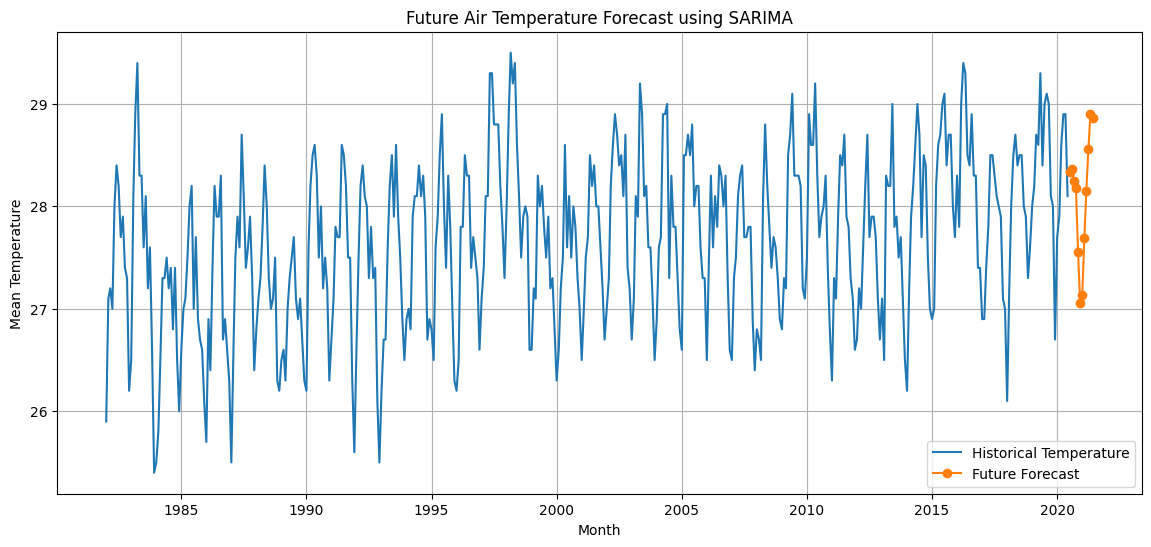

In [44]:
plt.figure(figsize=(14,6))

plt.plot(
    df.index,
    df['mean_temp'],
    label='Historical Temperature'
)

plt.plot(
    future_forecast_df['month'],
    future_forecast_df['forecasted_mean_temp'],
    marker='o',
    label='Future Forecast'
)

plt.title(
    f"Future Air Temperature Forecast using {best_model_name}"
)

plt.xlabel("Month")
plt.ylabel("Mean Temperature")

plt.legend()
plt.grid(True)

plt.show()

# 17.4 Save Forecast

In [45]:
output_path = "/content/future_air_temperature_forecast.csv"

future_forecast_df.to_csv(
    output_path,
    index=False
)

print("Forecast saved successfully:")
print(output_path)

Forecast saved successfully:
/content/future_air_temperature_forecast.csv


## Future Temperature Forecast

After selecting SARIMA as the final model, the model was trained using the complete historical dataset.

The trained SARIMA model was then used to forecast the monthly mean air temperature for the next 12 months.

The forecast results were presented in tabular and graphical form to clearly visualize the expected future temperature pattern.

# Challenges Faced

The following challenges were encountered during the project:

- Understanding and preparing the dataset for time series analysis.
- Maintaining the chronological order of observations during train-test splitting.
- Identifying the seasonal behavior present in monthly temperature data.
- Preparing sequential data appropriately for the LSTM model.
- Comparing statistical forecasting models with a deep learning model using consistent evaluation metrics.
- Handling numerical fitting issues while training the SARIMA model on the complete dataset.
- Selecting the final model based on objective evaluation metrics rather than choosing a model beforehand.

# Project Limitations

- The forecasting performance depends on the historical temperature patterns present in the dataset.
- Only the available historical temperature observations were used for forecasting.
- External factors that may influence air temperature were not included.
- Long-term changes in weather or climate conditions may affect future forecasting performance.

# Future Scope

The project can be further improved by:

- Including additional weather-related variables such as humidity, rainfall, pressure, and wind speed.
- Performing systematic hyperparameter tuning for ARIMA and SARIMA.
- Testing additional time series forecasting techniques.
- Using longer and more recent datasets for training.
- Deploying the forecasting model through a web-based application or dashboard.
- Continuously updating the model with new temperature observations.

# Conclusion

The Air Temperature Time Series Forecasting project successfully analyzed historical monthly mean air temperature data and developed forecasting models using ARIMA, SARIMA, and LSTM.

Exploratory data analysis was performed to understand the temperature trends and seasonal patterns. The dataset was divided chronologically into training and testing sets, and all three models were evaluated using MAE and RMSE.

Based on the model comparison results, SARIMA achieved the lowest forecasting error and was selected as the final model. Its ability to incorporate seasonal patterns made it suitable for the monthly temperature dataset.

The selected SARIMA model was trained using the complete historical dataset and used to forecast the monthly mean air temperature for the next 12 months.

This project demonstrates the practical application of time series analysis, seasonal forecasting, model evaluation, and machine learning techniques for predicting future air temperature.